# Software Defect Prediction - PROMISE dataset
End-to-end experiment notebook: data loading, cleaning, preprocessing, training of the five classifiers (Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, SVM), evaluation and artifact saving.

All heavy lifting lives in the reusable modules under `src/`, so the notebook, the CLI (`python -m src.train_models`) and the Streamlit app share exactly the same logic.

## 1. Setup

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import *
from src.preprocessing import *
from src.train_models import build_models, train_models, tune_hyperparameters, save_artifacts, write_test_data
from src.evaluate import *

set_global_seed(RANDOM_STATE)
setup_logging()
sns.set_theme(style='whitegrid')
print('Random seed:', RANDOM_STATE)

Random seed: 42


## 2. Load the dataset
The Kaggle collection `fracpete/promisedata` bundles the PROMISE / NASA MDP ARFF files. Kaggle needs an API token, so `python -m src.download_data` fetches the same JM1, KC1, KC2 and PC1 files from the OpenML mirror and merges them (all four share the same 21 McCabe / Halstead metrics).

In [2]:
raw = load_dataset()
print(raw.shape)
raw.head()

13:41:29 | INFO     | src.preprocessing | Loaded 14625 rows x 23 columns from D:\Muthu Learning\MTECH DS\Semester 2\Machine Learning\Assignments\Muthu-Assignment-2\Muthu_MachineLearning_Assignment-2\data\promise_defects.csv


(14625, 23)


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects,source_project
0,1.1,1.4,1.4,1.4,1.3,1.30,1.30,1.30,1.30,1.30,...,2,2,2,1.2,1.2,1.2,1.2,1.4,False,JM1
1,1.0,1.0,1.0,1.0,1.0,1.00,1.00,1.00,1.00,1.00,...,1,1,1,1.0,1.0,1.0,1.0,1.0,True,JM1
2,72.0,7.0,1.0,6.0,198.0,1134.13,0.05,20.31,55.85,23029.10,...,10,8,1,17.0,36.0,112.0,86.0,13.0,True,JM1
3,190.0,3.0,1.0,3.0,600.0,4348.76,0.06,17.06,254.87,74202.67,...,29,28,2,17.0,135.0,329.0,271.0,5.0,True,JM1
4,37.0,4.0,1.0,4.0,126.0,599.12,0.06,17.19,34.86,10297.30,...,1,6,0,11.0,16.0,76.0,50.0,7.0,True,JM1


In [3]:
print(raw[SOURCE_COL].value_counts(), '\n')
print('Raw class distribution:\n', raw[TARGET_COL].value_counts())
print('\nMissing cells per column:'); print(raw[FEATURE_COLUMNS].isna().sum()[lambda s: s > 0])

source_project
JM1    10885
KC1     2109
PC1     1109
KC2      522
Name: count, dtype: int64 

Raw class distribution:
 defects
False    12009
True      2616
Name: count, dtype: int64

Missing cells per column:
uniq_Op        5
uniq_Opnd      5
total_Op       5
total_Opnd     5
branchCount    5
dtype: int64


## 3. Cleaning
* convert the target to binary (`0` = non defective, `1` = defective)
* drop exact duplicate rows (the NASA data contains many)
* drop invalid records that violate basic metric rules (negative values, `v(g)` > `loc`, Halstead length != operators + operands, ...)
* missing metric values are kept and imputed with the **training** median after the split (no leakage)

In [4]:
clean, report = clean_data(raw)
pd.Series({k: v for k, v in report.items() if not isinstance(v, dict)})

13:41:29 | INFO     | src.preprocessing | Cleaning: 14625 loaded -> 3250 duplicates, 182 invalid removed -> 11193 rows


rows_loaded            14625
missing_cells             25
duplicates_removed      3250
invalid_removed          182
rows_final             11193
missing_cells_final       20
dtype: int64

In [5]:
pd.DataFrame(report['invalid_by_rule'].items(), columns=['Invalid-record rule', 'rows'])

,Invalid-record rule,rows
0,module without code (loc < 1),6
1,v(g) greater than loc,23
2,lOCode greater than loc,9
3,Halstead length != operators + operands,142
4,Halstead level l above 1,20


## 4. Exploratory analysis

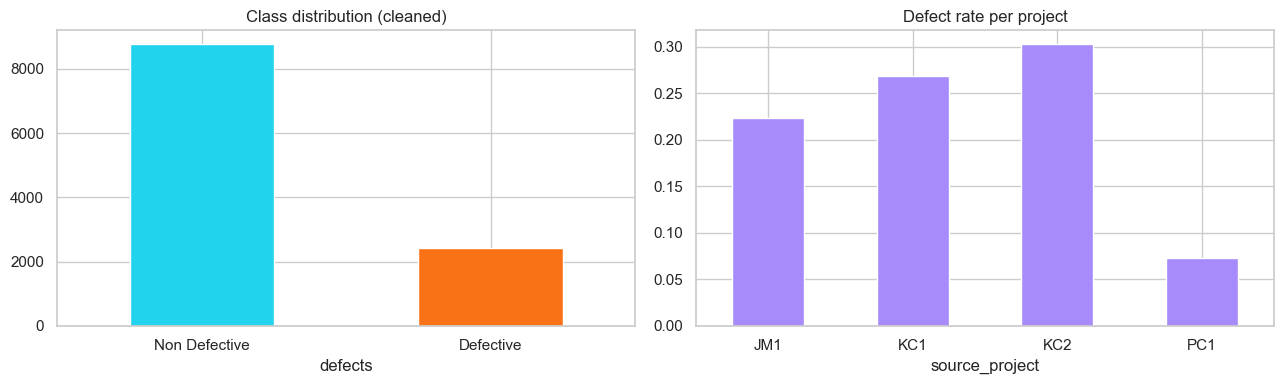

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
clean[TARGET_COL].map(CLASS_LABELS).value_counts().plot.bar(ax=ax[0], color=['#22D3EE', '#F97316'], rot=0)
ax[0].set_title('Class distribution (cleaned)')
clean.groupby(SOURCE_COL)[TARGET_COL].mean().plot.bar(ax=ax[1], color='#A78BFA', rot=0)
ax[1].set_title('Defect rate per project'); plt.tight_layout(); plt.show()

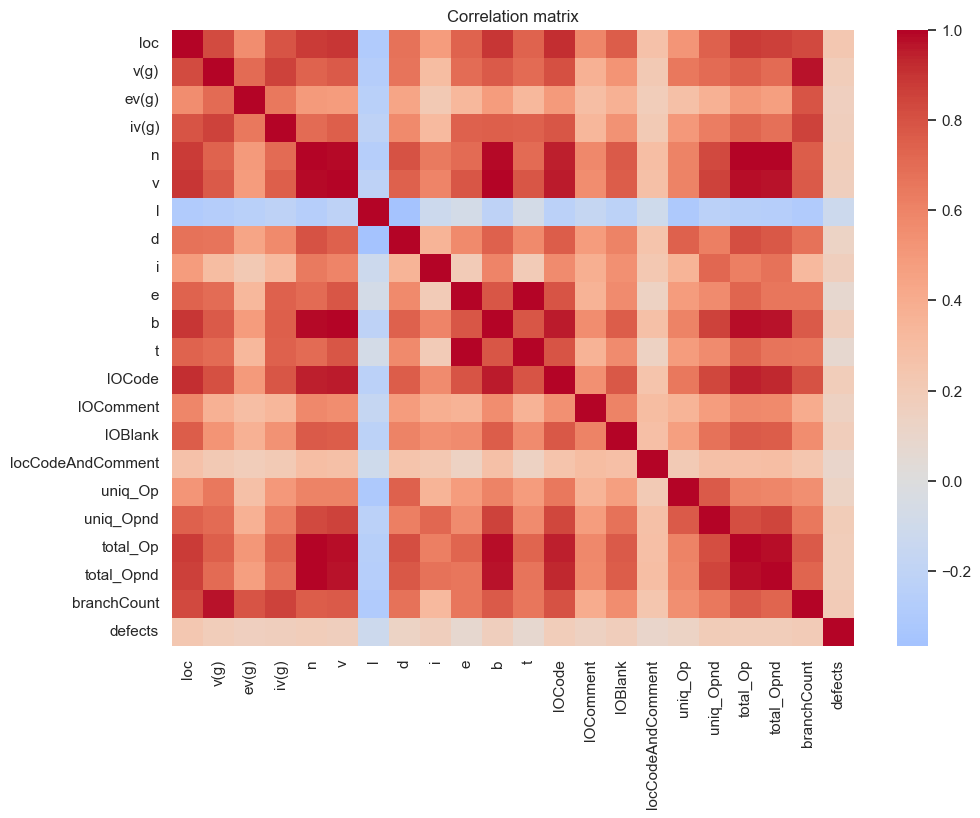

In [7]:
plt.figure(figsize=(11, 8))
sns.heatmap(clean[FEATURE_COLUMNS + [TARGET_COL]].corr(), cmap='coolwarm', center=0)
plt.title('Correlation matrix'); plt.show()

## 5. Preprocessing pipeline
Stratified 80/20 split -> median imputer -> `log1p` (the metrics are heavily right-skewed) -> `StandardScaler` (imputer and scaler fitted on train only) -> random over-sampling of the minority class in the training partition.

In [8]:
data = prepare_data()
print('Train (balanced):', data.X_train.shape, np.bincount(data.y_train))
print('Train (original):', data.X_train_unbalanced.shape, np.bincount(data.y_train_unbalanced))
print('Test            :', data.X_test.shape, np.bincount(data.y_test))
data.test_frame.head()

13:41:29 | INFO     | src.preprocessing | Loaded 14625 rows x 23 columns from D:\Muthu Learning\MTECH DS\Semester 2\Machine Learning\Assignments\Muthu-Assignment-2\Muthu_MachineLearning_Assignment-2\data\promise_defects.csv


13:41:29 | INFO     | src.preprocessing | Cleaning: 14625 loaded -> 3250 duplicates, 182 invalid removed -> 11193 rows


Train (balanced): (14008, 21) [7004 7004]
Train (original): (8954, 21) [7004 1950]
Test            : (2239, 21) [1751  488]


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,33.0,3.0,1.0,2.0,60.0,291.48,0.10,9.75,29.90,2841.92,...,17,5,8,0,13.0,16.0,36.0,24.0,5.0,0
1,5.0,1.0,1.0,1.0,13.0,44.97,0.23,4.38,10.28,196.76,...,5,0,1,0,7.0,4.0,8.0,5.0,1.0,0
2,19.0,3.0,3.0,2.0,0.0,0.00,0.00,0.00,0.00,0.00,...,0,0,0,0,0.0,0.0,0.0,0.0,5.0,0
3,8.0,4.0,3.0,1.0,31.0,126.71,0.07,14.40,8.80,1824.64,...,8,0,1,0,12.0,5.0,19.0,12.0,7.0,0
4,9.0,1.0,1.0,1.0,31.0,131.69,0.16,6.11,21.55,804.75,...,9,15,15,0,10.0,9.0,20.0,11.0,1.0,0


## 6. Hyper-parameter tuning and training of the five models
3-fold stratified cross-validation (ROC-AUC) on the **training** data only - over-sampling happens inside each fold and the hold-out set is never touched. The search reproduces `BEST_PARAMS` in `src/train_models.py`.

In [9]:
tuned = tune_hyperparameters(data)
tuned

13:41:30 | INFO     | src.train_models | Tuned Logistic Regression  CV AUC 0.7014 {'C': 10}


13:41:32 | INFO     | src.train_models | Tuned Decision Tree        CV AUC 0.6765 {'max_depth': 4, 'min_samples_leaf': 20}


13:41:40 | INFO     | src.train_models | Tuned KNN                  CV AUC 0.6912 {'n_neighbors': 101, 'weights': 'uniform'}


13:41:40 | INFO     | src.train_models | Tuned Naive Bayes          CV AUC 0.6717 {'var_smoothing': 0.1}


13:42:38 | INFO     | src.train_models | Tuned SVM                  CV AUC 0.6978 {'C': 1, 'gamma': 0.01}


{'Logistic Regression': {'C': 10},
 'Decision Tree': {'max_depth': 4, 'min_samples_leaf': 20},
 'KNN': {'n_neighbors': 101, 'weights': 'uniform'},
 'Naive Bayes': {'var_smoothing': 0.1},
 'SVM': {'C': 1, 'gamma': 0.01}}

In [10]:
models = train_models(data, params=tuned)
{name: type(m).__name__ for name, m in models.items()}

13:42:38 | INFO     | src.train_models | Training Logistic Regression on 14008 rows


13:42:39 | INFO     | src.train_models | Training Decision Tree on 14008 rows


13:42:39 | INFO     | src.train_models | Training KNN on 14008 rows


13:42:39 | INFO     | src.train_models | Training Naive Bayes on 14008 rows


13:42:39 | INFO     | src.train_models | Training SVM on 14008 rows


{'Logistic Regression': 'LogisticRegression',
 'Decision Tree': 'DecisionTreeClassifier',
 'KNN': 'KNeighborsClassifier',
 'Naive Bayes': 'GaussianNB',
 'SVM': 'SVC'}

## 7. Evaluation on the hold-out set

In [11]:
comparison = compare_models(models, data.X_test, data.y_test)
comparison.round(4)

13:43:12 | INFO     | src.evaluate | Logistic Regression  {'Accuracy': 0.6717, 'AUC': 0.7084, 'Precision': 0.3562, 'Recall': 0.627, 'F1': 0.4543, 'MCC': 0.2642}


13:43:12 | INFO     | src.evaluate | Decision Tree        {'Accuracy': 0.6632, 'AUC': 0.6813, 'Precision': 0.3432, 'Recall': 0.5963, 'F1': 0.4356, 'MCC': 0.2368}


13:43:12 | INFO     | src.evaluate | KNN                  {'Accuracy': 0.6396, 'AUC': 0.6889, 'Precision': 0.3323, 'Recall': 0.6475, 'F1': 0.4392, 'MCC': 0.2379}


13:43:12 | INFO     | src.evaluate | Naive Bayes          {'Accuracy': 0.7021, 'AUC': 0.6713, 'Precision': 0.3638, 'Recall': 0.4898, 'F1': 0.4175, 'MCC': 0.2276}


13:43:15 | INFO     | src.evaluate | SVM                  {'Accuracy': 0.6695, 'AUC': 0.6975, 'Precision': 0.3489, 'Recall': 0.5963, 'F1': 0.4402, 'MCC': 0.2444}


,ML Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.6717,0.7084,0.3562,0.6270,0.4543,0.2642
1,Decision Tree,0.6632,0.6813,0.3432,0.5963,0.4356,0.2368
2,KNN,0.6396,0.6889,0.3323,0.6475,0.4392,0.2379
3,Naive Bayes,0.7021,0.6713,0.3638,0.4898,0.4175,0.2276
4,SVM,0.6695,0.6975,0.3489,0.5963,0.4402,0.2444


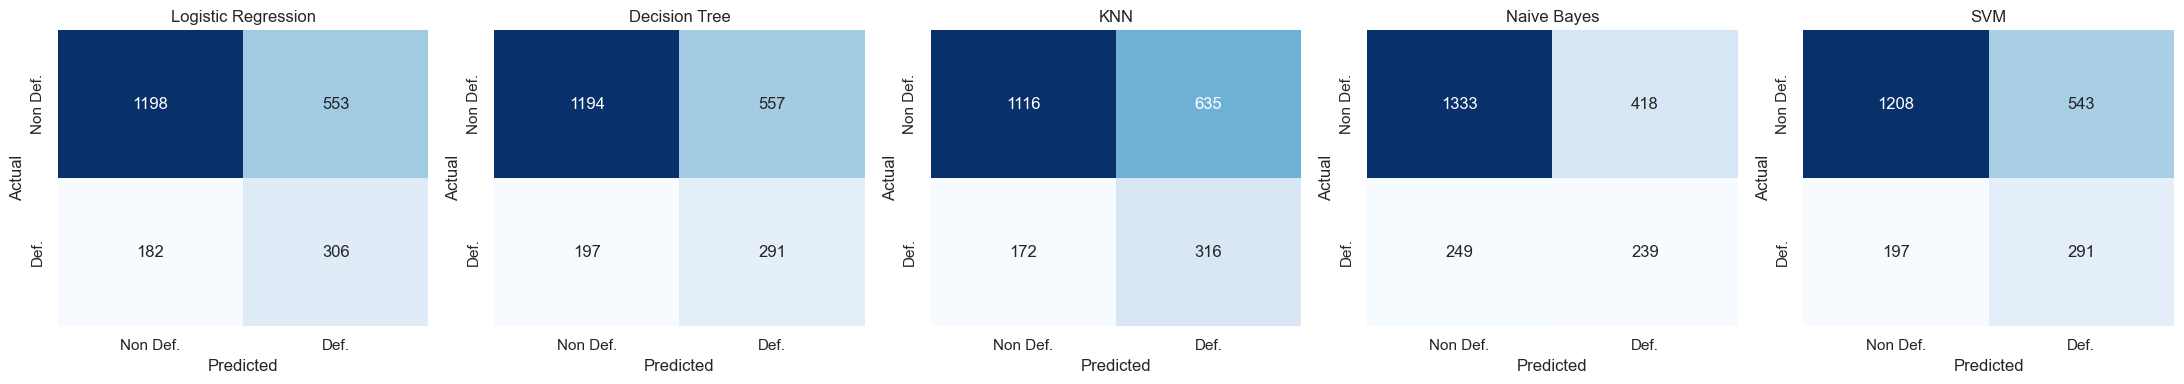

In [12]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = get_confusion_matrix(data.y_test, model.predict(data.X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Non Def.', 'Def.'], yticklabels=['Non Def.', 'Def.'])
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.show()

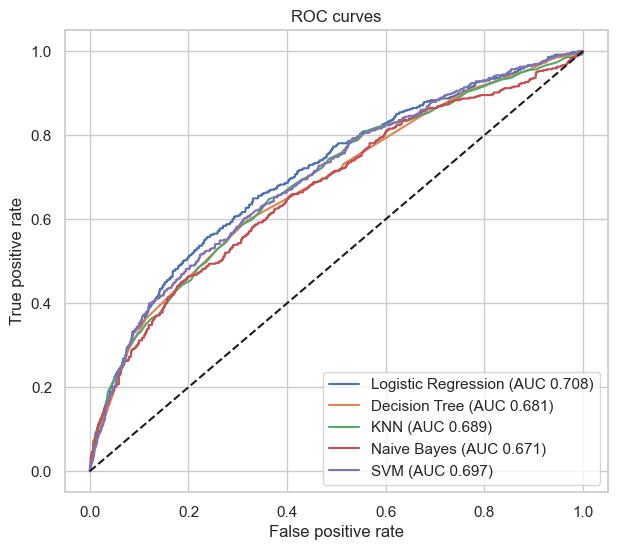

In [13]:
plt.figure(figsize=(7, 6))
for name, model in models.items():
    fpr, tpr, auc = get_roc_data(data.y_test, positive_scores(model, data.X_test))
    plt.plot(fpr, tpr, label=f'{name} (AUC {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--'); plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('ROC curves'); plt.legend(); plt.show()

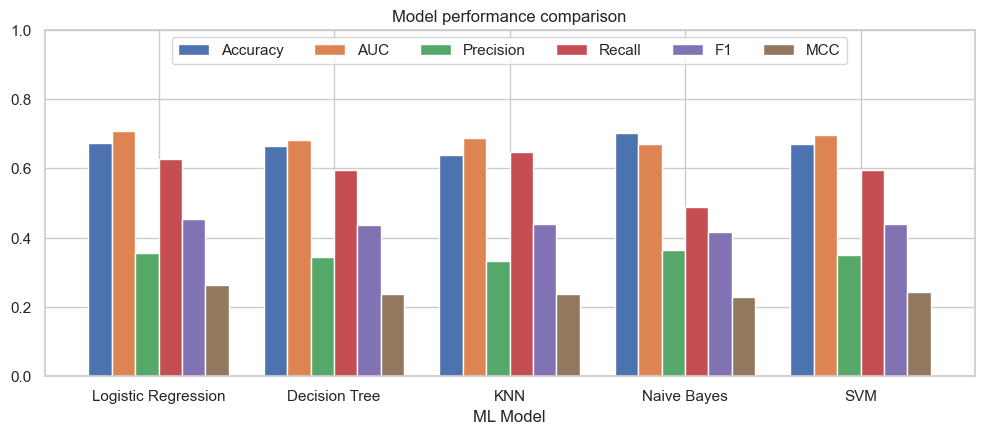

In [14]:
comparison.set_index('ML Model')[METRIC_NAMES].plot.bar(figsize=(12, 4.5), rot=0, width=0.8)
plt.title('Model performance comparison'); plt.ylim(0, 1); plt.legend(ncol=6, loc='upper center'); plt.show()

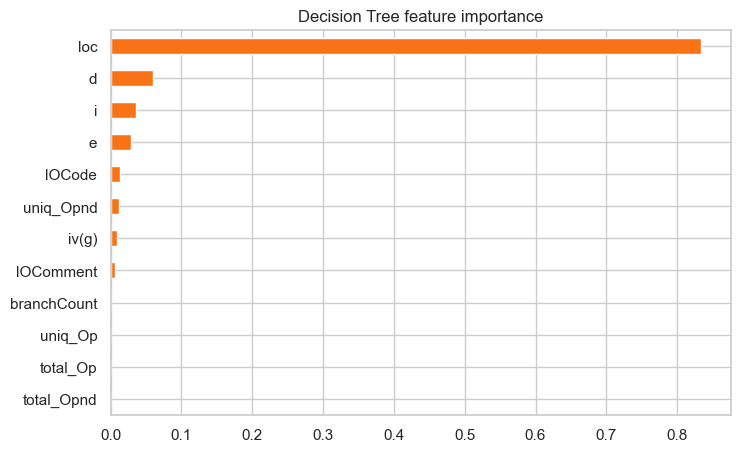

In [15]:
tree = models['Decision Tree']
importance = pd.Series(tree.feature_importances_, index=FEATURE_COLUMNS).sort_values()
importance.tail(12).plot.barh(figsize=(8, 5), color='#F97316'); plt.title('Decision Tree feature importance'); plt.show()

## 8. Ranking
Models are ranked by **MCC**, then **F1**, then **AUC**.

In [16]:
ranked = rank_models(comparison)
ranked.round(4)

,Rank,ML Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,1,Logistic Regression,0.6717,0.7084,0.3562,0.6270,0.4543,0.2642
1,2,SVM,0.6695,0.6975,0.3489,0.5963,0.4402,0.2444
2,3,KNN,0.6396,0.6889,0.3323,0.6475,0.4392,0.2379
3,4,Decision Tree,0.6632,0.6813,0.3432,0.5963,0.4356,0.2368
4,5,Naive Bayes,0.7021,0.6713,0.3638,0.4898,0.4175,0.2276


In [17]:
print('Best model:', ranked.loc[0, 'ML Model'])
for name in ranked['ML Model']:
    print('\n===', name)
    print(get_classification_report(data.y_test, models[name].predict(data.X_test)).round(3))

Best model: Logistic Regression

=== Logistic Regression
               precision  recall  f1-score  support
Non Defective      0.868   0.684     0.765     1751
Defective          0.356   0.627     0.454      488
accuracy           0.672   0.672     0.672        0
macro avg          0.612   0.656     0.610     2239
weighted avg       0.757   0.672     0.697     2239

=== SVM


               precision  recall  f1-score  support
Non Defective      0.860   0.690     0.766     1751
Defective          0.349   0.596     0.440      488
accuracy           0.669   0.669     0.669        0
macro avg          0.604   0.643     0.603     2239
weighted avg       0.748   0.669     0.695     2239

=== KNN
               precision  recall  f1-score  support
Non Defective      0.866   0.637     0.734     1751
Defective          0.332   0.648     0.439      488
accuracy           0.640   0.640     0.640        0
macro avg          0.599   0.642     0.587     2239
weighted avg       0.750   0.640     0.670     2239

=== Decision Tree
               precision  recall  f1-score  support
Non Defective      0.858   0.682     0.760     1751
Defective          0.343   0.596     0.436      488
accuracy           0.663   0.663     0.663        0
macro avg          0.601   0.639     0.598     2239
weighted avg       0.746   0.663     0.689     2239

=== Naive Bayes
               prec

## 9. Save models, scaler, imputer, encoders and `test_data.csv`

In [18]:
save_artifacts(models, data, comparison)
write_test_data(data)
sorted(p.name for p in MODEL_DIR.iterdir())

13:43:22 | INFO     | src.train_models | Artifacts written to D:\Muthu Learning\MTECH DS\Semester 2\Machine Learning\Assignments\Muthu-Assignment-2\Muthu_MachineLearning_Assignment-2\model


13:43:22 | INFO     | src.train_models | Wrote 2239 test rows to D:\Muthu Learning\MTECH DS\Semester 2\Machine Learning\Assignments\Muthu-Assignment-2\Muthu_MachineLearning_Assignment-2\test_data.csv


['decision_tree.pkl',
 'encoders.pkl',
 'imputer.pkl',
 'knn.pkl',
 'logistic_regression.pkl',
 'metadata.json',
 'metrics.csv',
 'naive_bayes.pkl',
 'scaler.pkl',
 'svm.pkl']